<a href="https://colab.research.google.com/github/chidhindistephenson/AI-Intelligent-Systems-Labs-2026/blob/main/Exercise_02_Iris_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# SWE 414 — Artificial Intelligence and Intelligent Systems

## Week 8: Exercise 2 — Iris Flower Classification

**Student Number:** B227786B  
**Course Code:** SWE 414  
**Programme:** Software Engineering

### Laboratory Objectives

1. Load and explore the Iris flower dataset.
2. Implement k-Nearest Neighbours (k-NN), Decision Tree and Support Vector Machine (SVM) classifiers.
3. Compare the classification performance of the three algorithms.
4. Evaluate models using accuracy, precision, recall, F1-score and confusion matrices.
5. Visualise and interpret classification decision boundaries.

### Tools and Libraries

- Python
- Google Colab
- NumPy
- pandas
- Matplotlib
- seaborn
- scikit-learn



### 2.1 Dataset Source and Description

The Iris dataset is a well-known supervised machine learning dataset originally introduced by Fisher (1936).

It contains 150 observations representing three Iris flower species:

- Iris setosa
- Iris versicolor
- Iris virginica

Each observation contains four numerical measurements:

1. Sepal length (cm)
2. Sepal width (cm)
3. Petal length (cm)
4. Petal width (cm)

The dataset is accessed using scikit-learn's built-in `load_iris()` function.

**Reference:**

Fisher, R.A. (1936) 'The use of multiple measurements in taxonomic problems', *Annals of Eugenics*, 7(2), pp. 179–188.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris(as_frame=True)

# Extract the dataset
df = iris.frame

# Display the first five observations
print("First Five Records:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display feature names
print("\nFeature Names:")
print(iris.feature_names)

# Display target classes
print("\nFlower Species:")
print(iris.target_names)

# Display dataset information
print("\nDataset Information:")
df.info()


First Five Records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset Shape: (150, 5)

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Flower Species:
['setosa' 'versicolor' 'virginica']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB



### 2.2 Data Quality Assessment

The dataset is examined for missing values, duplicate records, class distribution and descriptive statistics before classification.


In [2]:

# Display descriptive statistics
print("Descriptive Statistics:")
display(df.describe().round(2))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Display class distribution
print("\nClass Distribution:")
class_counts = df["target"].value_counts().sort_index()

for class_id, count in class_counts.items():
    print(f"{iris.target_names[class_id]}: {count}")


Descriptive Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate Records:
1

Class Distribution:
setosa: 50
versicolor: 50
virginica: 50



### 2.3 Data Preparation and Train-Test Split

The Iris dataset is divided into input features (X) and target labels (y).

An 80:20 stratified train-test split is used to preserve the proportion of each flower species in both datasets.

A fixed random state of 42 ensures reproducibility.

Feature standardisation will be applied through scikit-learn Pipelines for algorithms that are sensitive to feature scales.


In [3]:

from sklearn.model_selection import train_test_split

# Separate the input features and target labels
X = df.drop(columns=["target"])
y = df["target"]

# Create stratified training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)

Training class distribution:
target
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64



### 2.4 Classification Model Training

Three supervised classification algorithms are implemented:

1. **k-Nearest Neighbours (k-NN):** Classifies observations based on the majority class among their nearest neighbours.
2. **Decision Tree:** Learns decision rules by recursively splitting the feature space.
3. **Support Vector Machine (SVM):** Constructs decision boundaries that separate classes using an RBF kernel.

StandardScaler is included in the k-NN and SVM pipelines because these algorithms are sensitive to feature magnitudes.

All models are trained using the same training dataset for comparison.


In [4]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Define the three classification models
models = {
    "k-NN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", C=1.0))
    ])
}

# Train all three models
for name, classifier in models.items():
    classifier.fit(X_train, y_train)
    print(f"{name} trained successfully!")

print("\nAll classification models are ready.")


k-NN trained successfully!
Decision Tree trained successfully!
SVM trained successfully!

All classification models are ready.



### 2.5 Classification Performance Comparison

The three classifiers are evaluated using accuracy, precision, recall and F1-score.

Macro-averaged precision, recall and F1-score are used to give equal importance to each flower species.


In [5]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, classifier in models.items():
    y_pred = classifier.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Classification Model Comparison:")
display(results_df.round(4))


Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,k-NN,0.9333,0.9444,0.9333,0.9327
1,Decision Tree,0.9667,0.9697,0.9667,0.9666
2,SVM,0.9667,0.9697,0.9667,0.9666



### 2.6 Confusion Matrix Analysis

Confusion matrices are used to examine the classification performance of k-NN, Decision Tree and SVM for each Iris species.

The rows represent actual flower species, while the columns represent predicted species. Values along the main diagonal indicate correct classifications, whereas off-diagonal values represent classification errors.


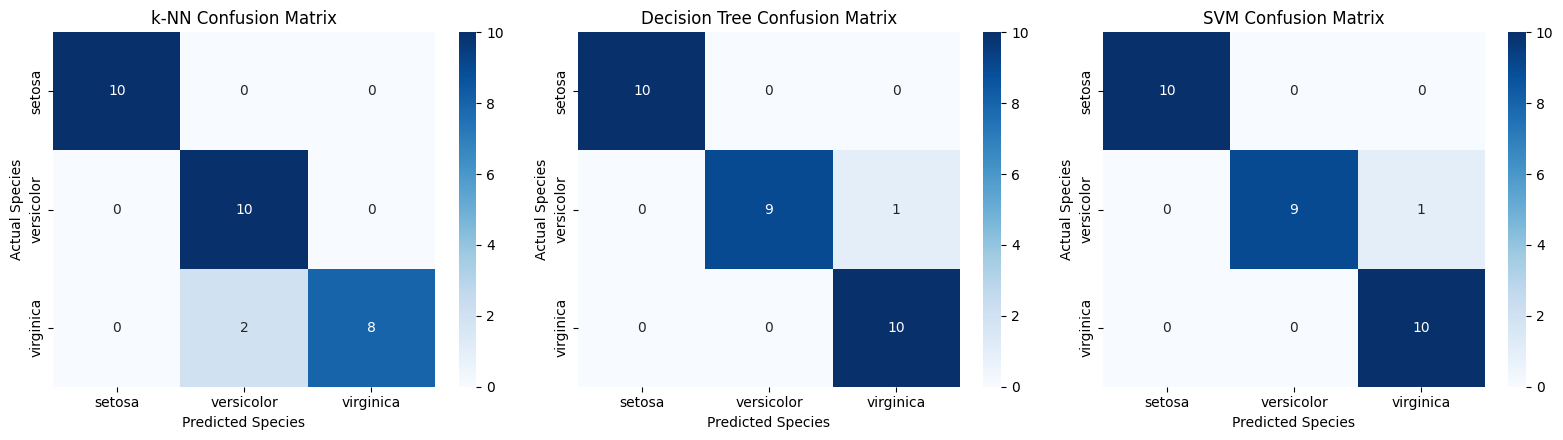

In [6]:

from sklearn.metrics import confusion_matrix, classification_report

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, classifier) in zip(axes, models.items()):
    y_pred = classifier.predict(X_test)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


In [7]:

for name, classifier in models.items():
    y_pred = classifier.predict(X_test)

    print("=" * 55)
    print(f"{name} - Classification Report")
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names,
            digits=4,
            zero_division=0
        )
    )


k-NN - Classification Report
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.8333    1.0000    0.9091        10
   virginica     1.0000    0.8000    0.8889        10

    accuracy                         0.9333        30
   macro avg     0.9444    0.9333    0.9327        30
weighted avg     0.9444    0.9333    0.9327        30

Decision Tree - Classification Report
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30

SVM - Classification Report
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000 


### 2.7 Decision Boundary Visualisation

Decision boundaries are visualised using petal length and petal width as the two input features.

Separate two-feature versions of the k-NN, Decision Tree and SVM classifiers are trained using the original training observations. This allows the decision regions to be displayed in two dimensions without modifying the four-feature models used for performance evaluation.

The visualisations illustrate how each algorithm partitions the feature space and distinguishes between the three Iris species.


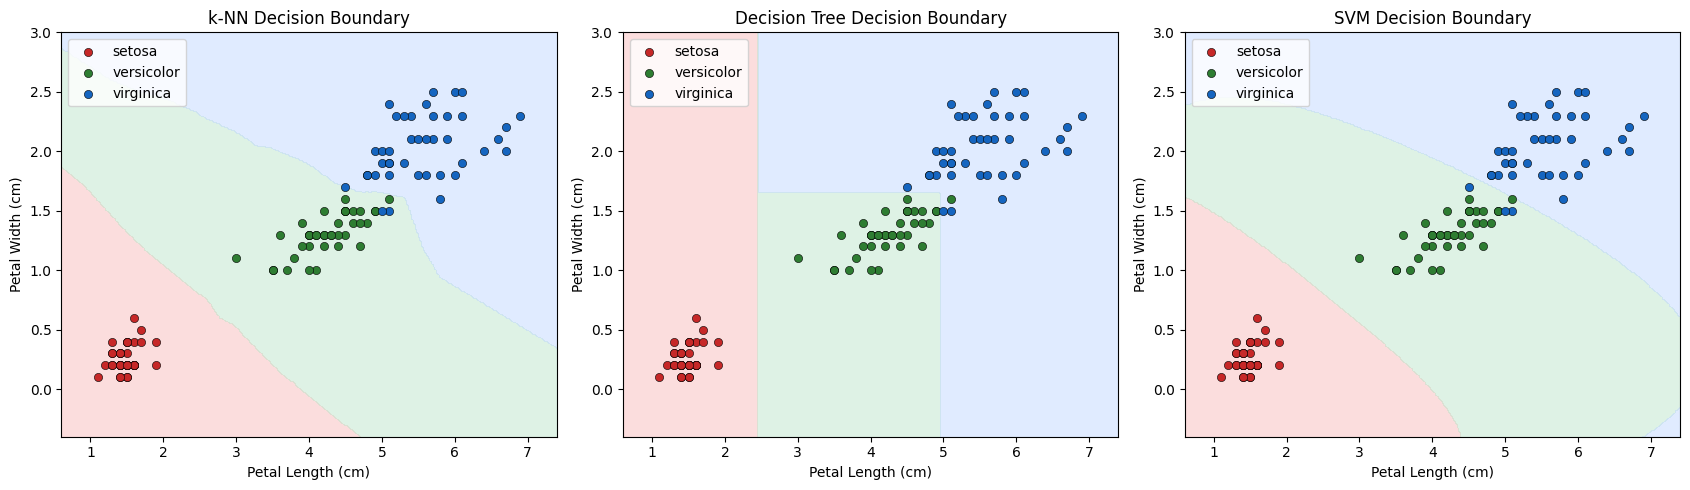

In [8]:

from matplotlib.colors import ListedColormap
from sklearn.base import clone

# Select two features for 2D visualisation
features_2d = ["petal length (cm)", "petal width (cm)"]
X_train_2d = X_train[features_2d]

# Train independent 2D versions of the classifiers
models_2d = {}

for name, classifier in models.items():
    model_2d = clone(classifier)
    model_2d.fit(X_train_2d, y_train)
    models_2d[name] = model_2d

# Create a grid covering the feature space
x_min = X_train_2d.iloc[:, 0].min() - 0.5
x_max = X_train_2d.iloc[:, 0].max() + 0.5
y_min = X_train_2d.iloc[:, 1].min() - 0.5
y_max = X_train_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)

# Define colours for the three Iris species
region_cmap = ListedColormap(["#f8b4b4", "#b7e4c7", "#bcd4ff"])
point_colors = ["#c62828", "#2e7d32", "#1565c0"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, classifier) in zip(axes, models_2d.items()):
    Z = classifier.predict(grid_points).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        alpha=0.45,
        cmap=region_cmap,
        levels=[-0.5, 0.5, 1.5, 2.5]
    )

    for class_id, species in enumerate(iris.target_names):
        mask = y_train == class_id

        ax.scatter(
            X_train_2d.loc[mask, features_2d[0]],
            X_train_2d.loc[mask, features_2d[1]],
            c=point_colors[class_id],
            label=species,
            edgecolors="black",
            linewidths=0.4,
            s=35
        )

    ax.set_title(f"{name} Decision Boundary")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend()

plt.tight_layout()
plt.show()


### 2.8 Results and Discussion

The experiment compared three supervised classification algorithms, namely k-Nearest Neighbours (k-NN), Decision Tree and Support Vector Machine (SVM), using the Iris dataset. The dataset contained 150 observations divided into 120 training samples and 30 testing samples through an 80:20 stratified split.

The results showed that Decision Tree and SVM achieved the highest classification accuracy of 96.67%, correctly classifying 29 out of 30 test samples. Both models achieved a macro-averaged precision of 0.9697, recall of 0.9667 and F1-score of 0.9666. The k-NN classifier achieved an accuracy of 93.33%, correctly classifying 28 samples, with a macro-averaged F1-score of 0.9327.

The confusion matrices revealed that all three algorithms correctly classified every Setosa observation. However, k-NN incorrectly classified two Virginica samples as Versicolor, while Decision Tree and SVM each misclassified one Versicolor sample as Virginica. This indicates that distinguishing between Versicolor and Virginica was more challenging than identifying Setosa.

The decision boundary visualisations demonstrated differences in how the algorithms separated the flower species. k-NN produced irregular decision regions influenced by neighbouring observations, while Decision Tree generated rectangular boundaries based on feature thresholds. SVM produced smoother, curved boundaries using the RBF kernel. The visualisations also showed clear separation of Setosa and some overlap between Versicolor and Virginica.

Although Decision Tree and SVM achieved better results than k-NN, the difference represented only one additional correctly classified test observation. Therefore, further evaluation using cross-validation would be useful before concluding that either algorithm consistently performs better.

### 2.9 Conclusion

The experiment successfully implemented and compared k-NN, Decision Tree and SVM classifiers for Iris flower classification. All three algorithms demonstrated strong predictive performance, with Decision Tree and SVM achieving the highest testing accuracy of 96.67%.

The confusion matrices and decision boundary visualisations helped explain the classification results and differences between the algorithms. The experiment demonstrated the effectiveness of supervised learning for multiclass classification and highlighted the importance of evaluating models using multiple performance metrics rather than accuracy alone.